# Practical 2 report: from relationships to predictive models

**Student:** Anna Gurina
**Date:** 20-Sep-2026  
**Practical:** 2 - Regression and evaluation


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

RANDOM_STATE = 170926

diabetes = load_diabetes(as_frame=True)
diabetes_df = diabetes.frame.copy()

diabetes_df.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


## 2. Data-preparation readiness

Complete the checklist before describing modelling results. Tick an item only after checking the data or documenting a justified decision.

### Scientific purpose and provenance

- [x] Is the biological question and prediction task stated clearly?
- [x] Is the unit of observation clear?
- [x] Do I know where the data came from, how they were generated, and under which access conditions they may be used?
- [x] Have I recorded the data version, processing history, and transformations already applied?

In [3]:
print(diabetes.DESCR[:1500])

.. _diabetes_dataset:

Diabetes dataset
----------------

Ten baseline variables, age, sex, body mass index, average blood
pressure, and six blood serum measurements were obtained for each of n =
442 diabetes patients, as well as the response of interest, a
quantitative measure of disease progression one year after baseline.

**Data Set Characteristics:**

:Number of Instances: 442

:Number of Attributes: First 10 columns are numeric predictive values

:Target: Column 11 is a quantitative measure of disease progression one year after baseline

:Attribute Information:
    - age     age in years
    - sex
    - bmi     body mass index
    - bp      average blood pressure
    - s1      tc, total serum cholesterol
    - s2      ldl, low-density lipoproteins
    - s3      hdl, high-density lipoproteins
    - s4      tch, total cholesterol / HDL
    - s5      ltg, possibly log of serum triglycerides level
    - s6      glu, blood sugar level

Note: Each of these 10 feature variables have bee

### Table shape and identifiers

- [x] Is the table tidy: one observation per row, one variable per column, and one value per cell?
- [x] If needed, have I transposed the original assay into the format expected by the analysis tool?
- [x] Are row names, column names, and identifiers clear, unique, and stable?
- [x] Can every feature and observation be traced to its source?
- [ ] Are the feature matrix and metadata aligned by an explicit identifier rather than row order?

In [4]:
print("Shape:", diabetes_df.shape)
print("Column names are unique:", diabetes_df.columns.is_unique)
print("Index is unique:", diabetes_df.index.is_unique)
print("Columns:", diabetes_df.columns.tolist())

Shape: (442, 11)
Column names are unique: True
Index is unique: True
Columns: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6', 'target']


### Types, values, and measurement meaning

- [x] Are numerical, categorical, ordinal, text, date, and identifier columns correctly classified?
- [x] Are units, scales, encodings, reference categories, and detection limits understood?
- [x] Have impossible values, inconsistent labels, unexpected categories, constant features, and extreme values been checked?
- [x] Are normalization, scaling, log transformation, and batch-correction steps documented?

In [5]:
diabetes_df.info()
print("Constant columns:", [column for column in diabetes_df.columns if diabetes_df[column].nunique() <= 1])

diabetes_df.describe().T.round(3)

<class 'pandas.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   s1      442 non-null    float64
 5   s2      442 non-null    float64
 6   s3      442 non-null    float64
 7   s4      442 non-null    float64
 8   s5      442 non-null    float64
 9   s6      442 non-null    float64
 10  target  442 non-null    float64
dtypes: float64(11)
memory usage: 38.1 KB
Constant columns: []


,count,mean,std,min,25%,50%,75%,max
age,442.0,-0.000,0.048,-0.107,-0.037,0.005,0.038,0.111
sex,442.0,0.000,0.048,-0.045,-0.045,-0.045,0.051,0.051
bmi,442.0,-0.000,0.048,-0.090,-0.034,-0.007,0.031,0.171
bp,442.0,-0.000,0.048,-0.112,-0.037,-0.006,0.036,0.132
s1,442.0,-0.000,0.048,-0.127,-0.034,-0.004,0.028,0.154
s2,442.0,0.000,0.048,-0.116,-0.030,-0.004,0.030,0.199
s3,442.0,-0.000,0.048,-0.102,-0.035,-0.007,0.029,0.181
s4,442.0,-0.000,0.048,-0.076,-0.039,-0.003,0.034,0.185
s5,442.0,0.000,0.048,-0.126,-0.033,-0.002,0.032,0.134
s6,442.0,0.000,0.048,-0.138,-0.033,-0.001,0.028,0.136


### Missing values

- [x] Have missing values been detected using all representations, not only `NaN`?
- [x] Have missing values been measured by row, column, and relevant group?
- [x] Do I know whether missingness is structural, technical, or plausibly related to biology or the target?
- [x] Have retention, removal, or imputation been justified?
- [x] If imputing, will the imputer be fitted on training data only?

In [5]:
missing_by_column = diabetes_df.isna().sum()
missing_by_row = diabetes_df.isna().sum(axis=1)

display(missing_by_column.to_frame("missing_count"))
print("Rows with at least one missing value:", int((missing_by_row > 0).sum()))

,missing_count
age,0
sex,0
bmi,0
bp,0
s1,0
s2,0
s3,0
s4,0
s5,0
s6,0


Rows with at least one missing value: 0


### Replicates, dependence, and grouping

- [ ] Have exact and near-duplicate observations been checked?
- [x] Are observations biological replicates, technical replicates, repeated measurements, pseudo-replicates, or independent samples?
- [x] Is the independent biological unit identified by a grouping variable?
- [x] Will related observations remain in the same train/validation/test split?
- [x] Is the provenance of synthetic or augmented observations recorded?

In [6]:
print("Exact duplicate rows:", int(diabetes_df.duplicated().sum()))
print("Duplicated predictor rows:", int(diabetes_df.drop(columns="target").duplicated().sum()))

Exact duplicate rows: 0
Duplicated predictor rows: 0


### Target, leakage, confounding, and reproducibility

- [x] Is the target defined before modelling?
- [x] Have identifiers, post-outcome variables, duplicated target information, and other leakage sources been excluded?
- [x] Have batch, site, subject, treatment, sex, age, time, and other possible confounders been considered?
- [x] Does the planned split represent the biological generalization question?
- [x] Are random seeds, software versions, file names, shapes, and preprocessing decisions recorded?

**Preparation summary:**

- Biological unit: one patient with diabetes
- Number of observations and features: 442 patients, 10 predictors
- Target and feature definition: target = disease progression one year after baseline; features = age, sex, bmi, bp, s1-s6 (blood serum measurements)
- Missing-value decision: no missing values, nothing to remove or impute
- Replicate/grouping decision: no duplicates; each row is treated as an independent patient, no grouping variable is available
- Main confounder or leakage source: age and sex are possible confounders, no leakage source found (target is not derived from the predictors)
- Train/test split and justification: random 80/20 split (as patients are independent)
- Remaining concerns: predictors are already standardized and s1-s6 are strongly correlated. 89 test patients - too shallow.

In [7]:
TARGET = "target"
predictors = [column for column in diabetes_df.columns if column != TARGET]

print("Target:", TARGET)
print("Predictors:", predictors)
print("Random seed:", RANDOM_STATE)
print("Shapes: X =", diabetes_df[predictors].shape, " y =", diabetes_df[TARGET].shape)

Target: target
Predictors: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']
Random seed: 170926
Shapes: X = (442, 10)  y = (442,)


## 3 Your  task: Diabetes regression

### 3.1 Data presentation

Identify:

- one observation;
- the target variable;
- predictor variables;
- dimensionality of the dataset;
- whether the predictors and target have physical units or transformed scales.

In [8]:
print("Number of observations:", diabetes_df.shape[0])
print("Number of predictors:", len(predictors))
print("Target:", TARGET)
print("Predictors:", predictors)

print("\nPredictor means (rounded):")
print(diabetes_df[predictors].mean().round(6).to_dict())
print("\nPredictor sum of squares:")
print((diabetes_df[predictors] ** 2).sum().round(3).to_dict())

Number of observations: 442
Number of predictors: 10
Target: target
Predictors: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']

Predictor means (rounded):
{'age': -0.0, 'sex': 0.0, 'bmi': -0.0, 'bp': -0.0, 's1': -0.0, 's2': 0.0, 's3': -0.0, 's4': -0.0, 's5': 0.0, 's6': 0.0}

Predictor sum of squares:
{'age': 1.0, 'sex': 1.0, 'bmi': 1.0, 'bp': 1.0, 's1': 1.0, 's2': 1.0, 's3': 1.0, 's4': 1.0, 's5': 1.0, 's6': 1.0}


**Comment:** one observation is one patient. The target is `target` (quantitative disease progression one year after baseline). The 10 predictors are `age`, `sex`, `bmi`, `bp` and six blood serum measurements `s1`-`s6`. The table has 442 rows and 10 predictors. The predictors have **no physical units**: `load_diabetes()` already centered them (mean 0) and scaled them (sum of squares = 1, so std = 0.048). The target stays on its original scale (25-346).

### 3.2 Descriptive analysis

- Summarize the target.
- Visualize its distribution.
- Visualize at least three predictor-target relationships.
- State the biological or predictive question addressed by each plot.

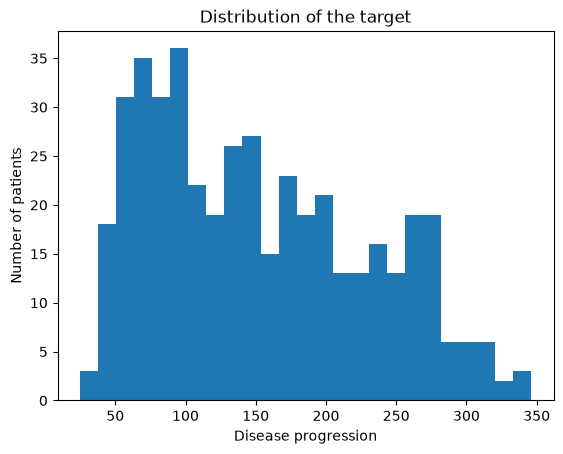

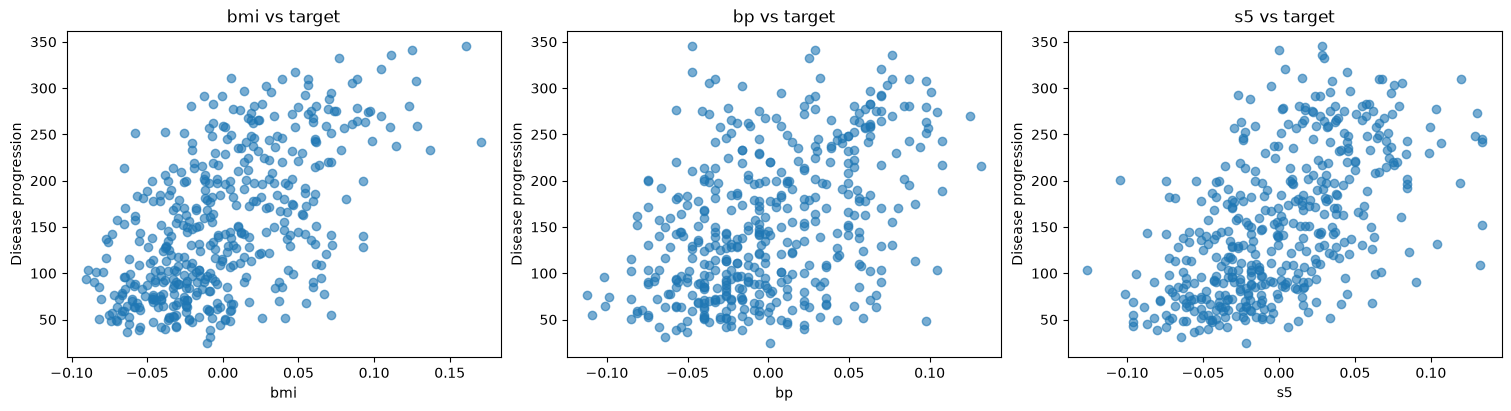

In [9]:
diabetes_df[TARGET].describe()

plt.hist(diabetes_df[TARGET], bins=25)
plt.xlabel("Disease progression")
plt.ylabel("Number of patients")
plt.title("Distribution of the target")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
for axis, predictor in zip(axes, ["bmi", "bp", "s5"]):
    axis.scatter(diabetes_df[predictor], diabetes_df[TARGET], alpha=0.6)
    axis.set_xlabel(predictor)
    axis.set_ylabel("Disease progression")
    axis.set_title(f"{predictor} vs target")
plt.show()

Interpretation: 
- the target has mean 152 and std 77, right-skewed
- Each plot asks whether a higher predictor value goes with higher disease progression: `bmi`, `bp`, `s5`. `bmi` and `s5` show a rather clear trend, `bp` does not show one. Seems like no single predictor can explain outcome.

### 3.3 Correlation

- Calculate correlation using ar least 2 different methods.
- Identify the predictor most strongly correlated with the target.
- Compare results.
- Explain why correlation is not sufficient for feature selection or causal interpretation.

In [10]:
pearson = diabetes_df.corr(method="pearson")[TARGET].drop(TARGET)
spearman = diabetes_df.corr(method="spearman")[TARGET].drop(TARGET)

corr_table = pd.DataFrame({"Pearson": pearson, "Spearman": spearman}).round(3)
corr_table.sort_values("Pearson", ascending=False)

,Pearson,Spearman
bmi,0.586,0.561
s5,0.566,0.589
bp,0.441,0.416
s4,0.430,0.449
s6,0.382,0.351
s1,0.212,0.232
age,0.188,0.198
s2,0.174,0.196
sex,0.043,0.037
s3,-0.395,-0.410


Interpretation: 
- the strongest Pearson correlation is `bmi` (0.586), then `s5` (0.566). 
- for Spearman: the sptrongest is `s5` (0.589), then `bmi` (0.561).
- `s3` - the only negative correlation (-0.40).
- Correlation is not enough for feature selection. It ignores that predictors are correlated, does not reveal cause.

### 4.4 Simple regression

Choose one predictor and fit a simple linear regression. Report and interpret:

- intercept;
- slope;
- the scale of the predictor;
- whether the slope is a causal effect.

In [11]:
simple_df = diabetes_df[["bmi", TARGET]].dropna()

X_simple = simple_df[["bmi"]]
y_simple = simple_df[TARGET]

simple_model = LinearRegression()
simple_model.fit(X_simple, y_simple)

print("Intercept:", simple_model.intercept_)
print("Slope:", simple_model.coef_[0])
print("Std of bmi:", X_simple["bmi"].std())

Intercept: 152.13348416289617
Slope: 949.4352603840388
Std of bmi: 0.047619047619047616


Interpretation: 
- intercept (152.1) is the mean target, because `bmi` is centered. 
- slope (949.4) is the change in progression per a unit of `bmi`. 
- so, if the standard deviation of `bmi` is 0.0476, the effect per 1 SD will be ~45 progression units (as bmi is standardised) - meaning that moving from an average-BMI patient to the one with 1 SD above average in BMI is associated with about x45 increase in predicted disease progression 

### 4.5 Residual diagnostics

Produce:

- observed versus predicted plot;
- residuals versus fitted plot;
- residual histogram;
- Q-Q plot.

Discuss linearity, homoscedasticity, residual normality, unusual observations, and any limitations of the diagnostics.

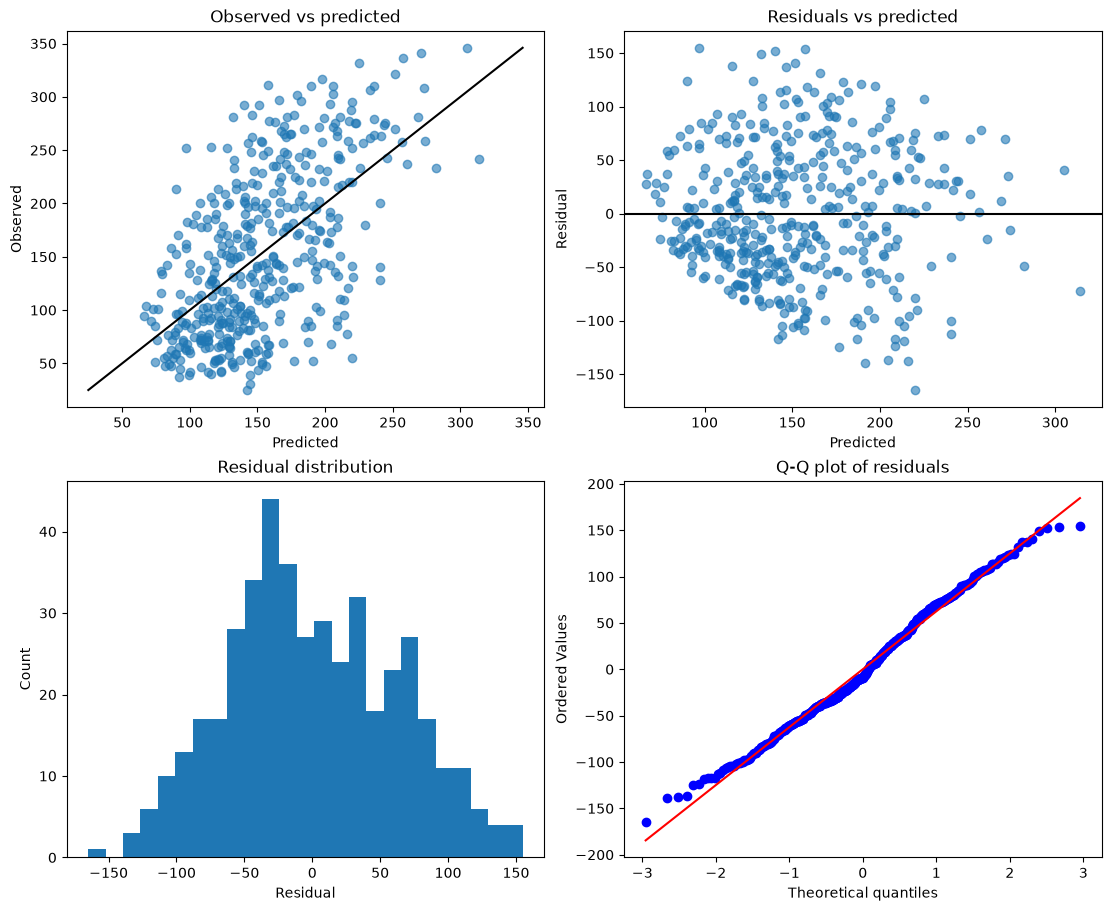

Mean residual: -2.62354240896037e-14
Largest absolute residuals: [149.1 151.9 153.5 154.9 164.9]


In [12]:
y_hat_simple = simple_model.predict(X_simple)
residuals = y_simple.to_numpy() - y_hat_simple

fig, axes = plt.subplots(2, 2, figsize=(11, 9), constrained_layout=True)

axes[0, 0].scatter(y_hat_simple, y_simple, alpha=0.6)
axes[0, 0].plot([y_simple.min(), y_simple.max()], [y_simple.min(), y_simple.max()], color="black")
axes[0, 0].set_xlabel("Predicted")
axes[0, 0].set_ylabel("Observed")
axes[0, 0].set_title("Observed vs predicted")

axes[0, 1].scatter(y_hat_simple, residuals, alpha=0.6)
axes[0, 1].axhline(0, color="black")
axes[0, 1].set_xlabel("Predicted")
axes[0, 1].set_ylabel("Residual")
axes[0, 1].set_title("Residuals vs predicted")

axes[1, 0].hist(residuals, bins=25)
axes[1, 0].set_xlabel("Residual")
axes[1, 0].set_ylabel("Count")
axes[1, 0].set_title("Residual distribution")

stats.probplot(residuals, dist="norm", plot=axes[1, 1])
axes[1, 1].set_title("Q-Q plot of residuals")
plt.show()

print("Mean residual:", residuals.mean())
print("Largest absolute residuals:", np.sort(np.abs(residuals))[-5:].round(1))

Interpretation:
- Linearity: residuals are centered on zero and show no strong curve, but the observed vs predicted cloud is wide, so a straight line explains only part of the variation.
- Homoscedasticity: the spread looks rather constant, with slightly less spread at the largest predictions.
- Normality: the histogram looks symmetric and the Q-Q plot follows the line, with small deviations in the tails.
- Unusual observations: residuals spread is rather wide (+-150-165)
- Limitation: visual checks of graphs are not enough fpr trustworthy conclusions.

### 4.6 Multiple regression and multicollinearity

Fit a model using all available predictors. Inspect:

- coefficients;
- predictor correlations;
- possible multicollinearity;
- whether standardized predictors change coefficient interpretation.

In [13]:
X_multiple = diabetes_df[predictors]
y_multiple = diabetes_df[TARGET]

multiple_model = LinearRegression()
multiple_model.fit(X_multiple, y_multiple)

coef_table = pd.DataFrame({"feature": predictors, "coefficient": multiple_model.coef_})
display(coef_table.round(1))
print("Intercept:", multiple_model.intercept_)

display(X_multiple.corr().round(2))

vif = {}
for predictor in predictors:
    others = [column for column in predictors if column != predictor]
    r2 = LinearRegression().fit(X_multiple[others], X_multiple[predictor]).score(X_multiple[others], X_multiple[predictor])
    vif[predictor] = 1 / (1 - r2)
pd.DataFrame({"VIF": vif}).round(2)

,feature,coefficient
0,age,-10.0
1,sex,-239.8
2,bmi,519.8
3,bp,324.4
4,s1,-792.2
5,s2,476.7
6,s3,101.0
7,s4,177.1
8,s5,751.3
9,s6,67.6


Intercept: 152.13348416289597


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
age,1.00,0.17,0.19,0.34,0.26,0.22,-0.08,0.20,0.27,0.30
sex,0.17,1.00,0.09,0.24,0.04,0.14,-0.38,0.33,0.15,0.21
bmi,0.19,0.09,1.00,0.40,0.25,0.26,-0.37,0.41,0.45,0.39
bp,0.34,0.24,0.40,1.00,0.24,0.19,-0.18,0.26,0.39,0.39
s1,0.26,0.04,0.25,0.24,1.00,0.90,0.05,0.54,0.52,0.33
s2,0.22,0.14,0.26,0.19,0.90,1.00,-0.20,0.66,0.32,0.29
s3,-0.08,-0.38,-0.37,-0.18,0.05,-0.20,1.00,-0.74,-0.40,-0.27
s4,0.20,0.33,0.41,0.26,0.54,0.66,-0.74,1.00,0.62,0.42
s5,0.27,0.15,0.45,0.39,0.52,0.32,-0.40,0.62,1.00,0.46
s6,0.30,0.21,0.39,0.39,0.33,0.29,-0.27,0.42,0.46,1.00


,VIF
age,1.22
sex,1.28
bmi,1.51
bp,1.46
s1,59.20
s2,39.19
s3,15.40
s4,8.89
s5,10.08
s6,1.48


Interpretation:
- largest coefficients: `s1` (-792), `s5` (+751), `bmi` (+520) and `s2` (+477)
- `s1` and `s2` are correlated with 0.90, also has large coefficients with opposite signs (multicollinearity)
- VIF follow same logic: `s1` 59, `s2` 39, `s3` 15, `s5` 10, `s4` 9. The collinearity is very high.
- model can still predict well - we don't know in which extent, but the predictors contribute to the ourcome prediction in correct direction if used together. The predictors are already standardized, so the coefficients are comparable in size.

### 4.7 Train/test evaluation

Create a justified train/test split and report MAE, MSE, RMSE, and $R^2$. Compare simple and multiple regression on test data.

Explain whether the split answers the intended biological or clinical generalization question.

In [14]:
def regression_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mean_squared_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)}


X = diabetes_df[predictors]
y = diabetes_df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE)

results = []
for model_name, features in [("Simple (bmi)", ["bmi"]), ("Multiple (all predictors)", predictors)]:
    model = LinearRegression()
    model.fit(X_train[features], y_train)
    for split_name, X_split, y_split in [("train", X_train, y_train), ("test", X_test, y_test)]:
        pred = model.predict(X_split[features])
        results.append({"model": model_name, "split": split_name, **regression_metrics(y_split, pred)})

results_df = pd.DataFrame(results)
results_df.round(3)

,model,split,MAE,MSE,RMSE,R2
0,Simple (bmi),train,52.188,3911.727,62.544,0.331
1,Simple (bmi),test,50.152,3828.665,61.876,0.362
2,Multiple (all predictors),train,43.488,2873.049,53.601,0.509
3,Multiple (all predictors),test,42.381,2850.190,53.387,0.525


Interpretation:
- Random 80/20 split is used (fixed seed).
- The multiple regression is better on test data (RMSE 53.4, MAE 42.4, $R^2$ = 0.525) than the simple `bmi` regression (RMSE 61.9, MAE 50.2, $R^2$ = 0.362).
- Train and test scores are similar, so we can believe no overfitting happens.
- Model would work for "does the model work for new patients from the same population?" problem for independent patients.

### 4.8 Independent-task conclusion

Answer:

1. Which model generalized better?
2. Did adding more variables help?
3. Are any regression assumptions questionable?
4. Are coefficient interpretations straightforward?
5. What is one important limitation of the dataset or model?

Remember that the predictors from `load_diabetes()` are already standardized.

Answers:

1. The multiple regression: test RMSE 53.4 vs 61.9 and $R^2$ 0.525 vs 0.362.
2. Yes, about 0.16 more $R^2$ on test data, and train and test scores stayed close.
3. Residuals look rather centered, constant in spread and close to normal for the simple model, but the fit is weak. In the multiple model the predictors `s1`-`s6` are very collinear (VIF mostly way above 10, up to 59).
4. No. The predictors are standardized and have no physical units, some collinear predictors have large coefficients with opposite signs.
5. Limitation: only 442 patients, one random split with 89 test patients, no external validation, the model explains only half of the variance.